In [46]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
from datetime import datetime

In [54]:
path_fsm=r'data\FSM_all.nc'
path_snow=r'data\snow_metrics.nc'
ds_terrain = xr.open_dataset(path_fsm,decode_times=True)
ds_snow = xr.open_dataset(path_snow,decode_times=True)

altitudes = ds_terrain['dem'].values.flatten() ## On récupére les données d'altitude
aspect = ds_terrain['aspect'].values.flatten()
forest = ds_terrain["forest"].values.flatten()


primary_mask = (forest >= 0.1)
primary_mask = np.where(primary_mask,1,np.nan)

for s in range(len(ds_snow.season)) :
    curr_season = ds_snow.season[s]

    meb_peak = ds_snow["Peak_SWE"].sel(simulation='MXT_FOR', season = curr_season).values.flatten() 
    fsm_peak = ds_snow["Peak_SWE"].sel(simulation='FSM_FOR', season = curr_season).values.flatten() 
    meb_scd = ds_snow["Snow_duration"].sel(simulation='MXT_FOR', season = curr_season).values.flatten() 
    fsm_scd = ds_snow["Snow_duration"].sel(simulation='FSM_FOR', season = curr_season).values.flatten() 
    
    primary_mask = np.where(meb_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(fsm_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(meb_scd > 2, primary_mask, np.nan)
    primary_mask = np.where(fsm_scd > 2, primary_mask, np.nan)

## On définit les cadrants
angle = np.array([22.5, 67.5, 112.5, 157.5, 202.5, 247.5, 292.5, 337.5])  ## ne pas modifier (Angles pour avoir 8 cadrants)
alt = np.arange(1000, 2801, 300)   ## à modifier si on veut aller de 500 à 3500m


C:\Users\mazzottg\AppData\Local\Temp\ipykernel_32132\1415035342.py:18: RuntimeWarning: Mean of empty slice
  SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan


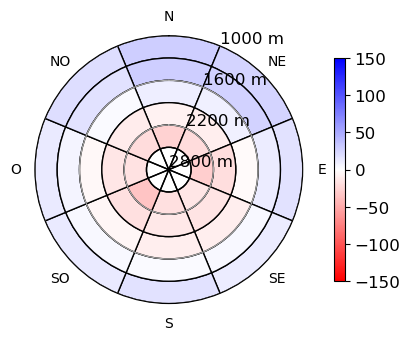

In [48]:

# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Peak_SWE"].sel(simulation='MXT_FOR').mean(dim="season", skipna=True).values.flatten() - ds_snow["Peak_SWE"].sel(simulation='FSM_FOR').mean(dim="season", skipna=True).values.flatten() 
variable = np.where(primary_mask ==1 ,variable,np.nan)

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5)) ) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) )
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-150,vmax=150)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200, 1600, 1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
mois = False
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-150,150)

C:\Users\mazzottg\AppData\Local\Temp\ipykernel_32132\2820932115.py:20: RuntimeWarning: Mean of empty slice
  SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan


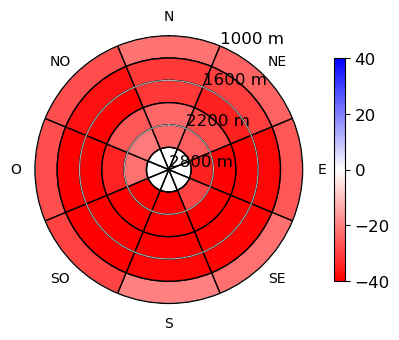

In [49]:
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Snow_duration"].sel(simulation='MXT_FOR').mean(dim="season", skipna=True).values.flatten() - ds_snow["Snow_duration"].sel(simulation='FSM_FOR').mean(dim="season", skipna=True).values.flatten() 
variable = np.where(primary_mask ==1 ,variable,np.nan)



for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5))) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) )
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-40,vmax=40)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200, 1600, 1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
mois = False
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-40,40)


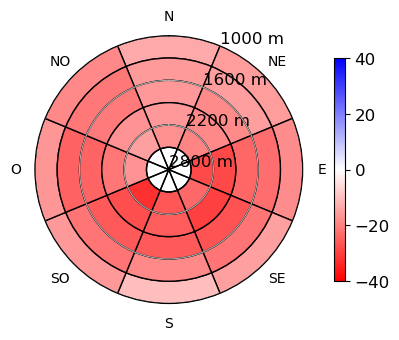

In [35]:
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["SDD"].sel(simulation='MXT_FOR').mean(dim="season", skipna=True).dt.dayofyear.values.flatten() - ds_snow["SDD"].sel(simulation='FSM_FOR').mean(dim="season", skipna=True).dt.dayofyear.values.flatten() 
variable = np.where(primary_mask ==1 ,variable,np.nan)

for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5)) & (forest >= 0.1)) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) & (forest >= 0.1))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-40,vmax=40)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200, 1600, 1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
mois = False
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-40,40)

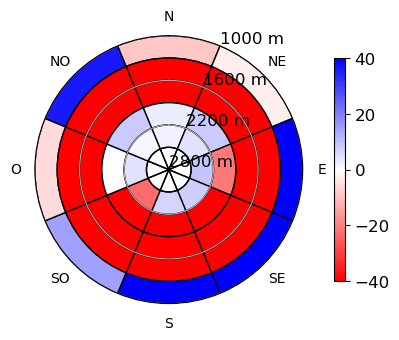

In [57]:
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["SSD"].sel(simulation='MXT_FOR').mean(dim="season", skipna=True).dt.dayofyear.values.flatten() - ds_snow["SSD"].sel(simulation='FSM_FOR').mean(dim="season", skipna=True).dt.dayofyear.values.flatten() 
variable = ds_snow["SSD"].sel(simulation='MXT_FOR', season= '2017/2018').dt.dayofyear.values.flatten() - ds_snow["SSD"].sel(simulation='FSM_FOR', season= '2017/2018').dt.dayofyear.values.flatten() 
variable = ds_snow["SSD"].sel(simulation='MXT_FOR', season= '2022/2023').dt.dayofyear.values.flatten() - ds_snow["SSD"].sel(simulation='FSM_FOR', season= '2022/2023').dt.dayofyear.values.flatten() 

variable = np.where(primary_mask ==1 ,variable,np.nan)



for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5)) & (forest >= 0.1)) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]) & (forest >= 0.1))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-40,vmax=40)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200, 1600, 1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
mois = False
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-40,40)

In [51]:
forest = ds_terrain["forest"].values


primary_mask = (forest >= 0.1)
primary_mask = np.where(primary_mask,1,np.nan)

for s in range(len(ds_snow.season)) :
    curr_season = ds_snow.season[s]

    meb_peak = ds_snow["Peak_SWE"].sel(simulation='MXT_FOR', season = curr_season).values
    fsm_peak = ds_snow["Peak_SWE"].sel(simulation='FSM_FOR', season = curr_season).values
    meb_scd = ds_snow["Snow_duration"].sel(simulation='MXT_FOR', season = curr_season).values
    fsm_scd = ds_snow["Snow_duration"].sel(simulation='FSM_FOR', season = curr_season).values
    
    primary_mask = np.where(meb_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(fsm_peak > 0.1, primary_mask, np.nan)
    primary_mask = np.where(meb_scd > 2, primary_mask, np.nan)
    primary_mask = np.where(fsm_scd > 2, primary_mask, np.nan)

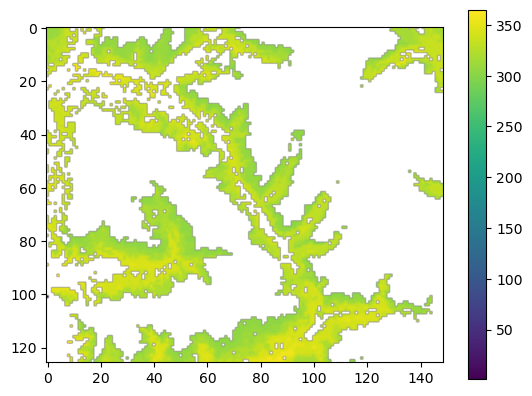

In [52]:
variable = ds_snow["SSD"].sel(simulation='MEB_FOR').mean(dim="season", skipna=True).dt.dayofyear.values # .flatten() - ds_snow["SSD"].sel(simulation='FSM_FOR').mean(dim="season", skipna=True).dt.dayofyear.values.flatten() 
variable = np.where(primary_mask ==1 ,variable,np.nan)


plt.imshow(variable)
plt.colorbar()

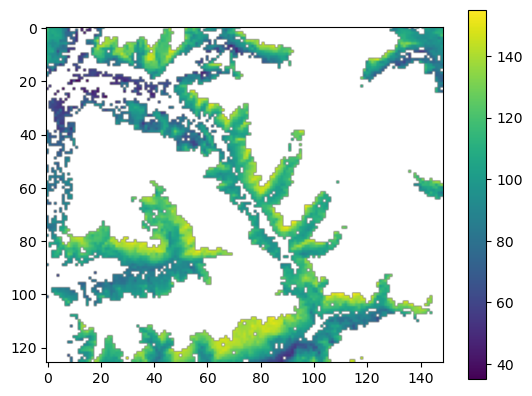

In [43]:
variable = ds_snow["SDD"].sel(simulation='MXT_FOR').mean(dim="season", skipna=True).dt.dayofyear.values # .flatten() - ds_snow["SSD"].sel(simulation='FSM_FOR').mean(dim="season", skipna=True).dt.dayofyear.values.flatten() 
variable = np.where(primary_mask ==1 ,variable,np.nan)


plt.imshow(variable)
plt.colorbar()

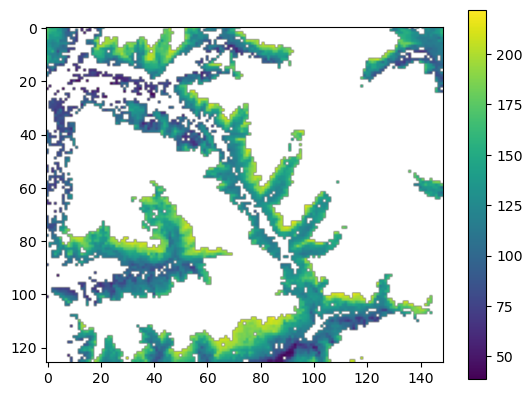

In [42]:
variable = ds_snow["Snow_duration"].sel(simulation='MXT_FOR').mean(dim="season", skipna=True).values # .flatten() - ds_snow["SSD"].sel(simulation='FSM_FOR').mean(dim="season", skipna=True).dt.dayofyear.values.flatten() 
variable = np.where(primary_mask ==1 ,variable,np.nan)


plt.imshow(variable)
plt.colorbar()

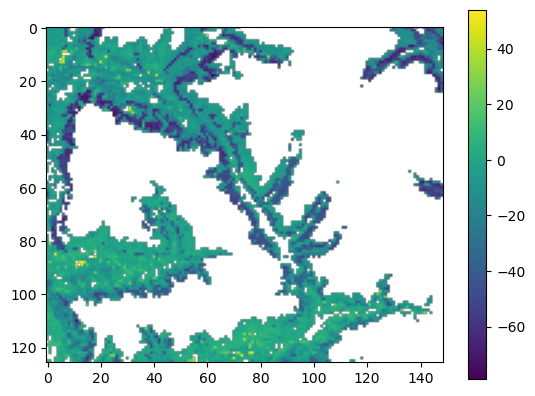

In [ ]:
curr_season = '2018/2019'
plt.imshow(ds_snow["Snow_duration"].sel(simulation='MEB_FOR', season = curr_season).values-ds_snow["Snow_duration"].sel(simulation='FSM_FOR', season = curr_season).values)
plt.colorbar()

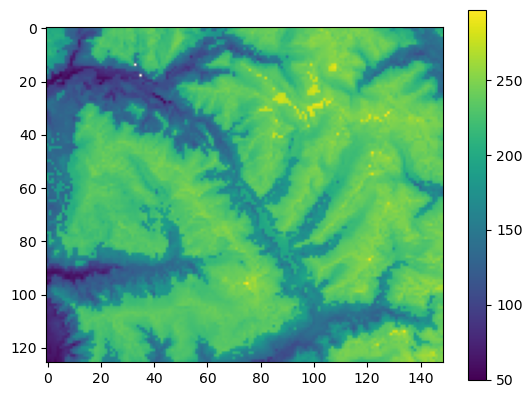

In [29]:
plt.imshow(ds_snow["Snow_duration"].sel(simulation='MEB_FOR', season = curr_season).values)#-ds_snow["Snow_duration"].sel(simulation='FSM_FOR', season = curr_season).values)
plt.colorbar()


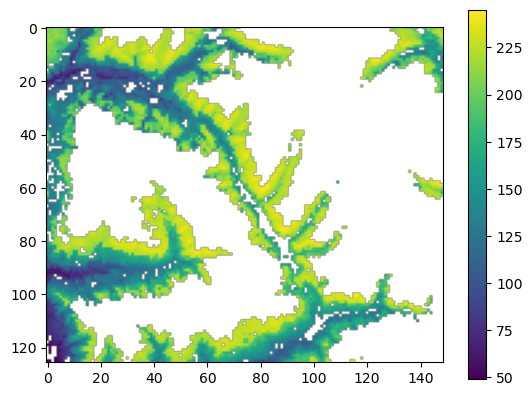

In [30]:

plt.imshow(ds_snow["Snow_duration"].sel(simulation='FSM_FOR', season = curr_season).values)#-ds_snow["Snow_duration"].sel(simulation='FSM_FOR', season = curr_season).values)
plt.colorbar()

C:\Users\mazzottg\AppData\Local\Temp\ipykernel_32132\3419588162.py:3: RuntimeWarning: invalid value encountered in subtract
  variable = ds_snow["Ablation_rate"].sel(simulation='MXT_FOR').mean(dim="season", skipna=True).values.flatten() - ds_snow["Ablation_rate"].sel(simulation='FSM_FOR').mean(dim="season", skipna=True).values.flatten()
C:\Users\mazzottg\AppData\Local\Temp\ipykernel_32132\3419588162.py:20: RuntimeWarning: Mean of empty slice
  SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan


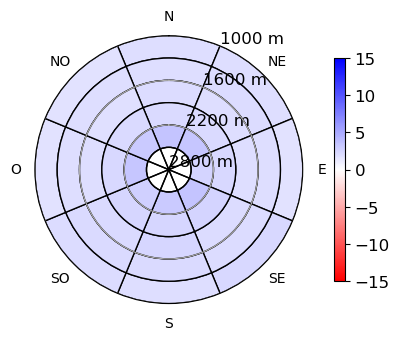

In [34]:
# Matrice pour stocker la moyenne de SWE par alt et orientation
SWE_matrix = np.zeros((len(alt)-1,len(angle)))
variable = ds_snow["Ablation_rate"].sel(simulation='MXT_FOR').mean(dim="season", skipna=True).values.flatten() - ds_snow["Ablation_rate"].sel(simulation='FSM_FOR').mean(dim="season", skipna=True).values.flatten() 
variable = np.where(np.isfinite(variable), variable, np.nan)
variable = np.where(primary_mask ==1 ,variable,np.nan)


for i in range(len(alt)-1):# on se balade dans les altitudes
    for j in range(len(angle)): #on se balade dans les angles on part de 1 car le secteur nord est traité aprés
        if j == 0 :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                ((aspect >= 337.5) | (aspect < 22.5)) ) 
        else :
            mask = (
                (altitudes >= alt[i]) & (altitudes < alt[i + 1]) & 
                (aspect >= angle[j-1]) & (aspect < angle[j]))
            
        SWE_values = variable[mask]
        SWE_matrix[i, j] = np.nanmean(SWE_values) if SWE_values.size > 0 else np.nan ##On moyenne en ignorant les nan et si pas de de valeur on rempli avec des nan 
        #SWE_matrix[i, 0]=np.count_nonzero(~np.isnan(SWE_values)) ## à utiliser si on veut le nombre exemple classe de LAI


fig,ax = plt.subplots(1,1,figsize=(4,4),subplot_kw={'projection':'polar'})
norm=mcolors.Normalize(vmin=-15,vmax=15)
cmap=plt.get_cmap('bwr_r')

for i in range(len(alt)-1):
    for j in range(len(angle)):
        if j==0: ## secteur Nord
            theta1, theta2=np.radians([337.5,22.5])
            r1, r2 = alt[i], alt[i + 1]

            ax.bar(0,  # Position angulaire centrale
            r2 - r1,  # Largeur radiale
            width=theta2 + theta2 , # Largeur angulaire
            bottom=r1,  # Début de l'anneau
            color=cmap(norm(SWE_matrix[i, j] )),  
            edgecolor='black')
        else:
            theta1, theta2 = np.radians([angle[j-1], angle[j]])
            r1, r2 = alt[i], alt[i + 1]
            ax.bar((theta1 + theta2) / 2,  
            r2 - r1,  
            width=theta2 - theta1,  
            bottom=r1,  
            color=cmap(norm(SWE_matrix[i, j])),  
            edgecolor='black')

        
   # ax.set_ylim(2200, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_ylim(2800, 1000) # Permet de commencer par le bas et finir par le haut
ax.set_theta_zero_location('N')  # On place le Nord en haut
ax.set_theta_direction(-1)  # Sens horaire

# Paramétres pour afficher les orientations
label=['N','NE','E','SE','S','SO','O','NO']
angles=np.array([0,45,90,135,180,225,270,315])
ax.set_xticks(np.radians(angles))
ax.set_xticklabels(label,fontsize=10)
ax.grid(False,axis='x')## enleve la barre
# Ajouter les cercles d'altitude
# rticks =[2200,1800,1400,1000]
rticks =[2800,2200, 1600, 1000]
ax.set_yticks(rticks)
ax.set_yticklabels([f"{int(alt)} m" for alt in rticks],fontsize=12)
# Paramétres pour la colorbar
mois = False
unite = 'mm'
sm = plt.cm.ScalarMappable(cmap=cmap)
sm.set_array(SWE_matrix)
cbar = fig.colorbar(sm, ax=ax, orientation='vertical',fraction=0.036,pad=0.1)
cbar.ax.tick_params(labelsize=12)
sm.set_clim(-15,15)

In [48]:
SWE_matrix

array([[3.69719692, 3.50055024, 3.30999119, 2.76166881, 3.11996744,
        2.88080264, 2.74907373, 2.91910016],
       [3.43182145, 3.52198982, 3.26220175, 3.21113693, 3.57613993,
        3.33081013, 3.13775233, 3.17115804],
       [3.4234185 , 3.3471381 , 3.17962966, 3.34400659, 3.73580277,
        3.35870393, 3.09787008, 3.11272659],
       [3.80966632, 3.57504617, 3.22288866, 3.40602799, 3.87388971,
        3.35668594, 3.28309639, 3.46652913],
       [4.78263002, 4.38474557, 3.95385944, 4.36499988, 4.52587449,
        3.89257899, 4.31279836, 4.02447044],
       [       nan,        nan,        nan,        nan,        nan,
               nan,        nan,        nan]])

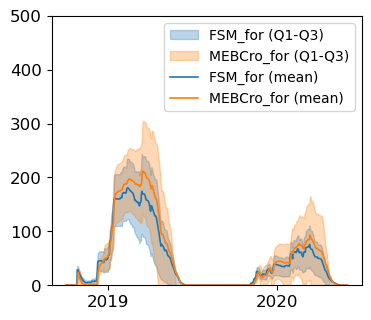

In [5]:
# TIME SERIES ANALYSES
path_fsm=r'data\FSM_all_corr.nc'
path_meb=r'data\MEBCroXT_for.nc'

ds_fsm = xr.open_dataset(path_fsm,decode_times=True)
ds_meb = xr.open_dataset(path_meb,decode_times=True)

# time series for specific elevation band - FSM-ALL vs. MEB-DEF -- FIGURE 4
start_time = datetime(2018, 10, 2, 6, 0)
end_time = datetime(2020, 5, 31, 6, 0)
mask = ((ds_fsm['forest'] >= 0.1) & (ds_fsm['lai'] >= 4.5))


masked_data_fsm = ds_fsm["swet_for"].where(mask).sel(time=slice(start_time, end_time))
masked_data_meb= ds_meb["swet_all"].where(mask).sel(time=slice(start_time, end_time))
mean_fsm = masked_data_fsm.mean(dim=("yy", "xx"), skipna=True)
mean_meb = masked_data_meb.mean(dim=("yy", "xx"), skipna=True)
q25_fsm = masked_data_fsm.quantile(0.25, dim=['yy', 'xx'])
q75_fsm = masked_data_fsm.quantile(0.75, dim=['yy', 'xx'])
q25_meb = masked_data_meb.quantile(0.25, dim=['yy', 'xx'])
q75_meb = masked_data_meb.quantile(0.75, dim=['yy', 'xx'])

# Extract time axis
time_fsm = q25_fsm['time'].values
time_meb = q25_meb['time'].values


# Plot using matplotlib
fig, ax = plt.subplots(1, 1, figsize=(4, 3.5), sharex=True)

# Plot quantile envelopes
ax.fill_between(time_fsm, q25_fsm.values, q75_fsm.values, alpha=0.3, color='tab:blue', label='FSM_for (Q1-Q3)')
ax.fill_between(time_meb, q25_meb.values, q75_meb.values, alpha=0.3, color='tab:orange', label='MEBCro_for (Q1-Q3)')

ax.plot(time_fsm, mean_fsm.values, color='tab:blue', linewidth=1.2, label='FSM_for (mean)')
ax.plot(time_meb, mean_meb.values, color='tab:orange', linewidth=1.2, label='MEBCro_for (mean)')

ax.legend()
ax.tick_params(labelsize=12)
ax.set_ylim(0,500)
#ax.set_xticklabels(fontsize=12)
#ax.set_yticklabels(lafontsize=12)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

# fig.text(0.02, 0.5, 'SWE [mm]', va='center', rotation='vertical',fontsize = 12)

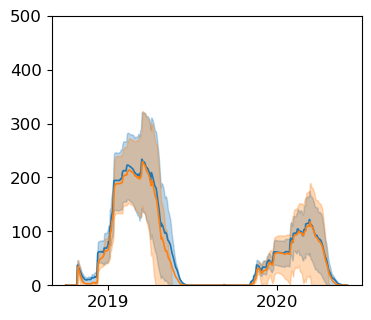

In [6]:

# time series for specific elevation band - FSM-ALL vs. MEB-DEF -- FIGURE 4
mask = ((ds_fsm['forest'] >= 0.1) & (ds_fsm['lai'] <= 3.5) & (ds_fsm['lai'] >= 2.5))


masked_data_fsm = ds_fsm["swet_for"].where(mask).sel(time=slice(start_time, end_time))
masked_data_meb= ds_meb["swet_all"].where(mask).sel(time=slice(start_time, end_time))
mean_fsm = masked_data_fsm.mean(dim=("yy", "xx"), skipna=True)
mean_meb = masked_data_meb.mean(dim=("yy", "xx"), skipna=True)
q25_fsm = masked_data_fsm.quantile(0.25, dim=['yy', 'xx'])
q75_fsm = masked_data_fsm.quantile(0.75, dim=['yy', 'xx'])
q25_meb = masked_data_meb.quantile(0.25, dim=['yy', 'xx'])
q75_meb = masked_data_meb.quantile(0.75, dim=['yy', 'xx'])

# Extract time axis
time_fsm = q25_fsm['time'].values
time_meb = q25_meb['time'].values


# Plot using matplotlib
fig, ax = plt.subplots(1, 1, figsize=(4, 3.5), sharex=True)

# Plot quantile envelopes
ax.fill_between(time_fsm, q25_fsm.values, q75_fsm.values, alpha=0.3, color='tab:blue', label='FSM_opn (Q1-Q3)')
ax.fill_between(time_meb, q25_meb.values, q75_meb.values, alpha=0.3, color='tab:orange', label='Cro_opn (Q1-Q3)')

ax.plot(time_fsm, mean_fsm.values, color='tab:blue', linewidth=1.2, label='FSM_opn (mean)')
ax.plot(time_meb, mean_meb.values, color='tab:orange', linewidth=1.2, label='Cro_opm (mean)')

#ax.legend()
ax.tick_params(labelsize=12)
ax.set_ylim(0,500)
#ax.set_xticklabels(fontsize=12)
#ax.set_yticklabels(lafontsize=12)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

#fig.text(0.02, 0.5, 'SWE [mm]', va='center', rotation='vertical',fontsize = 12)

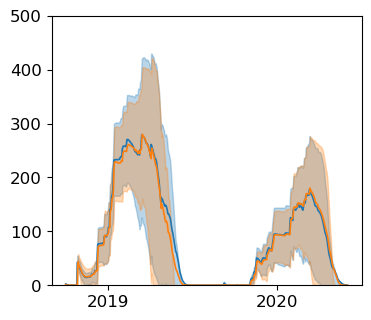

In [7]:

# time series for specific elevation band - FSM-ALL vs. MEB-DEF -- FIGURE 4
mask = ((ds_fsm['forest'] >= 0.1) & (ds_fsm['lai'] <= 1.5))


masked_data_fsm = ds_fsm["swet_for"].where(mask).sel(time=slice(start_time, end_time))
masked_data_meb= ds_meb["swet_all"].where(mask).sel(time=slice(start_time, end_time))
mean_fsm = masked_data_fsm.mean(dim=("yy", "xx"), skipna=True)
mean_meb = masked_data_meb.mean(dim=("yy", "xx"), skipna=True)
q25_fsm = masked_data_fsm.quantile(0.25, dim=['yy', 'xx'])
q75_fsm = masked_data_fsm.quantile(0.75, dim=['yy', 'xx'])
q25_meb = masked_data_meb.quantile(0.25, dim=['yy', 'xx'])
q75_meb = masked_data_meb.quantile(0.75, dim=['yy', 'xx'])

# Extract time axis
time_fsm = q25_fsm['time'].values
time_meb = q25_meb['time'].values


# Plot using matplotlib
fig, ax = plt.subplots(1, 1, figsize=(4, 3.5), sharex=True)

# Plot quantile envelopes
ax.fill_between(time_fsm, q25_fsm.values, q75_fsm.values, alpha=0.3, color='tab:blue', label='FSM_opn (Q1-Q3)')
ax.fill_between(time_meb, q25_meb.values, q75_meb.values, alpha=0.3, color='tab:orange', label='Cro_opn (Q1-Q3)')

ax.plot(time_fsm, mean_fsm.values, color='tab:blue', linewidth=1.2, label='FSM_opn (mean)')
ax.plot(time_meb, mean_meb.values, color='tab:orange', linewidth=1.2, label='Cro_opm (mean)')

#ax.legend()
ax.tick_params(labelsize=12)
ax.set_ylim(0,500)
#ax.set_xticklabels(fontsize=12)
#ax.set_yticklabels(lafontsize=12)
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

#fig.text(0.02, 0.5, 'SWE [mm]', va='center', rotation='vertical',fontsize = 12)